# Final Experimental Results (Corrected)
**Deep Learning-Assisted Reinforcement Learning for Budget-Constrained Satellite Telemetry Investigation**

Consolidates the verified outputs of notebook 01 (preprocessing), 02 (LSTM autoencoder), 03 (DQN on the fixed
event split) and 05 (5-fold cross-validation over all events, ablation and budget sweep).
Every number below is read from the saved result files; nothing is typed by hand.

**Run order:** 01 → 02 → 03 → 05 → 06 → 04 (this notebook reads the outputs of 05 and 06).

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

PROJECT = Path.cwd().parent
OUT = PROJECT / "outputs"; PLOTS = OUT / "04_plots"; RES = OUT / "07_results"
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.grid": True, "grid.alpha": 0.3})

pre = pd.read_csv(OUT / "02_preprocessing" / "preprocessing_summary.csv")
split = pd.read_csv(OUT / "03_splits" / "split_summary.csv")
lstm_cfg = json.load(open(OUT / "05_lstm_autoencoder" / "lstm_config.json"))
lstm = pd.read_csv(OUT / "05_lstm_autoencoder" / "lstm_detection_results.csv")
det = pd.read_csv(OUT / "06_rl_dqn" / "lstm_event_detection_by_split.csv")
seeds = pd.read_csv(OUT / "06_rl_dqn" / "dqn_seed_summary.csv")
val_cmp = pd.read_csv(RES / "validation_comparison.csv"); test_cmp = pd.read_csv(RES / "test_comparison.csv")
test_sub = pd.read_csv(RES / "test_comparison_excl_12ch.csv"); stats = pd.read_csv(RES / "test_statistical_tests.csv")
per_case = pd.read_csv(RES / "per_case_results_test.csv")
cfg = pd.read_csv(RES / "experiment_configuration.csv")
EXT = OUT / "09_extended_experiments"
ext_cfg = json.load(open(EXT / "extended_config.json"))
abl = pd.read_csv(EXT / "cv_ablation_budget5.csv"); abl_t = pd.read_csv(EXT / "cv_ablation_tests.csv")
sweep = pd.read_csv(EXT / "cv_budget_sweep.csv"); sweep_t = pd.read_csv(EXT / "cv_budget_sweep_tests.csv")
detcmp = pd.read_csv(EXT / "detector_score_comparison.csv")
IMP = OUT / "10_improved_pipeline"; imp_cfg = json.load(open(IMP / "improved_config.json"))
imp = pd.read_csv(IMP / ("cv_overlapping_augmented_budget5.csv" if "augmentation" in imp_cfg["chosen"] else "cv_overlapping_plain_budget5.csv"))
imp_t = pd.read_csv(IMP / "cv_chosen_tests_budget5.csv"); e2e = pd.read_csv(IMP / "end_to_end_168_events.csv")
imp_sw = pd.read_csv(IMP / "cv_budget_sweep.csv"); imp_swt = pd.read_csv(IMP / "cv_budget_sweep_tests.csv")
cov = pd.read_csv(IMP / "event_detection_coverage_summary.csv", index_col=0)

## 1. Data and preprocessing

In [2]:
print(pre.to_string(index=False)); print(); print(split.to_string(index=False))

                        Parameter                                                      Value
                          Dataset                                          ESA-ADB Mission 1
                Selected channels                                                         12
                  Time resolution                                                 90 seconds
               Interpolation rule gaps <= 3 samples (4.5 min) only; longer gaps left missing
                   Telemetry rows                                                    4909440
                 Telemetry period                 2000-01-01 00:00:00 -> 2013-12-31 23:58:30
                   Anomaly events                                                        168
               Annotation records                                                       1306
     Event split (train/val/test)                                                  117/25/26
       Known-anomaly coverage (%)                                     

## 2. LSTM autoencoder anomaly scoring

In [3]:
print({k: lstm_cfg[k] for k in ["window", "clip_sigma", "threshold", "best_epoch", "best_val_mse", "epochs_run"]})
print(lstm[["Split", "Clean_windows", "Anomaly_windows", "Precision", "Recall", "F1", "PR_AUC", "ROC_AUC", "False_positive_rate"]]
      .round(4).to_string(index=False))
print("\nEvents with at least one detected window (= investigation cases):")
print(det.to_string(index=False))

{'window': 128, 'clip_sigma': 10.0, 'threshold': 0.01861966773867607, 'best_epoch': 89, 'best_val_mse': 0.014542881399393082, 'epochs_run': 100}
     Split  Clean_windows  Anomaly_windows  Precision  Recall     F1  PR_AUC  ROC_AUC  False_positive_rate
Validation           5712              740     0.7991  0.4946 0.6110  0.6359   0.8100               0.0161
      Test           5282              491     0.7481  0.3992 0.5206  0.5174   0.7446               0.0125

Events with at least one detected window (= investigation cases):
     Split  Events  LSTM_detected_events  Detection_%
     Train     117                    90        76.92
Validation      25                    20        80.00
      Test      26                    20        76.92


## 3. Channel investigation at budget = 5

In [4]:
def fmt(t):
    d = t.copy()
    for m in ["TotalReward", "Hits", "Precision_at_5", "Recall_at_5", "UnnecessaryInvestigations"]:
        d[m] = [f"{v:.3f} ± {s:.3f}" if s > 0 else f"{v:.3f}" for v, s in zip(t[m], t[f"{m}_std"])]
    return d[["Method", "Cases", "TotalReward", "Hits", "Precision_at_5", "Recall_at_5", "UnnecessaryInvestigations"]]
print("VALIDATION\n", fmt(val_cmp).to_string(index=False))
print("\nTEST (all cases)\n", fmt(test_cmp).to_string(index=False))
print("\nTEST (excluding 12-channel events)\n", fmt(test_sub).to_string(index=False))
print("\nPaired Wilcoxon tests on test hits\n", stats.round(4).to_string(index=False))
print("\nDQN seeds:\n", seeds.to_string(index=False))

VALIDATION
         Method  Cases TotalReward  Hits Precision_at_5 Recall_at_5 UnnecessaryInvestigations
           DQN     20       3.500 4.250          0.850       0.880                     0.750
Fixed Priority     20       0.700 2.850          0.570       0.545                     2.150
   LSTM-Greedy     20       2.700 3.850          0.770       0.760                     1.150
        Random     20      -0.421 2.289          0.458       0.416                     2.711
        Oracle     20       3.500 4.250          0.850       0.880                     0.750

TEST (all cases)
         Method  Cases   TotalReward          Hits Precision_at_5   Recall_at_5 UnnecessaryInvestigations
           DQN     20 3.180 ± 0.271 4.090 ± 0.136  0.818 ± 0.027 0.719 ± 0.028             0.910 ± 0.136
Fixed Priority     20         2.300         3.650          0.730         0.586                     1.350
   LSTM-Greedy     20         2.900         3.950          0.790         0.698                  

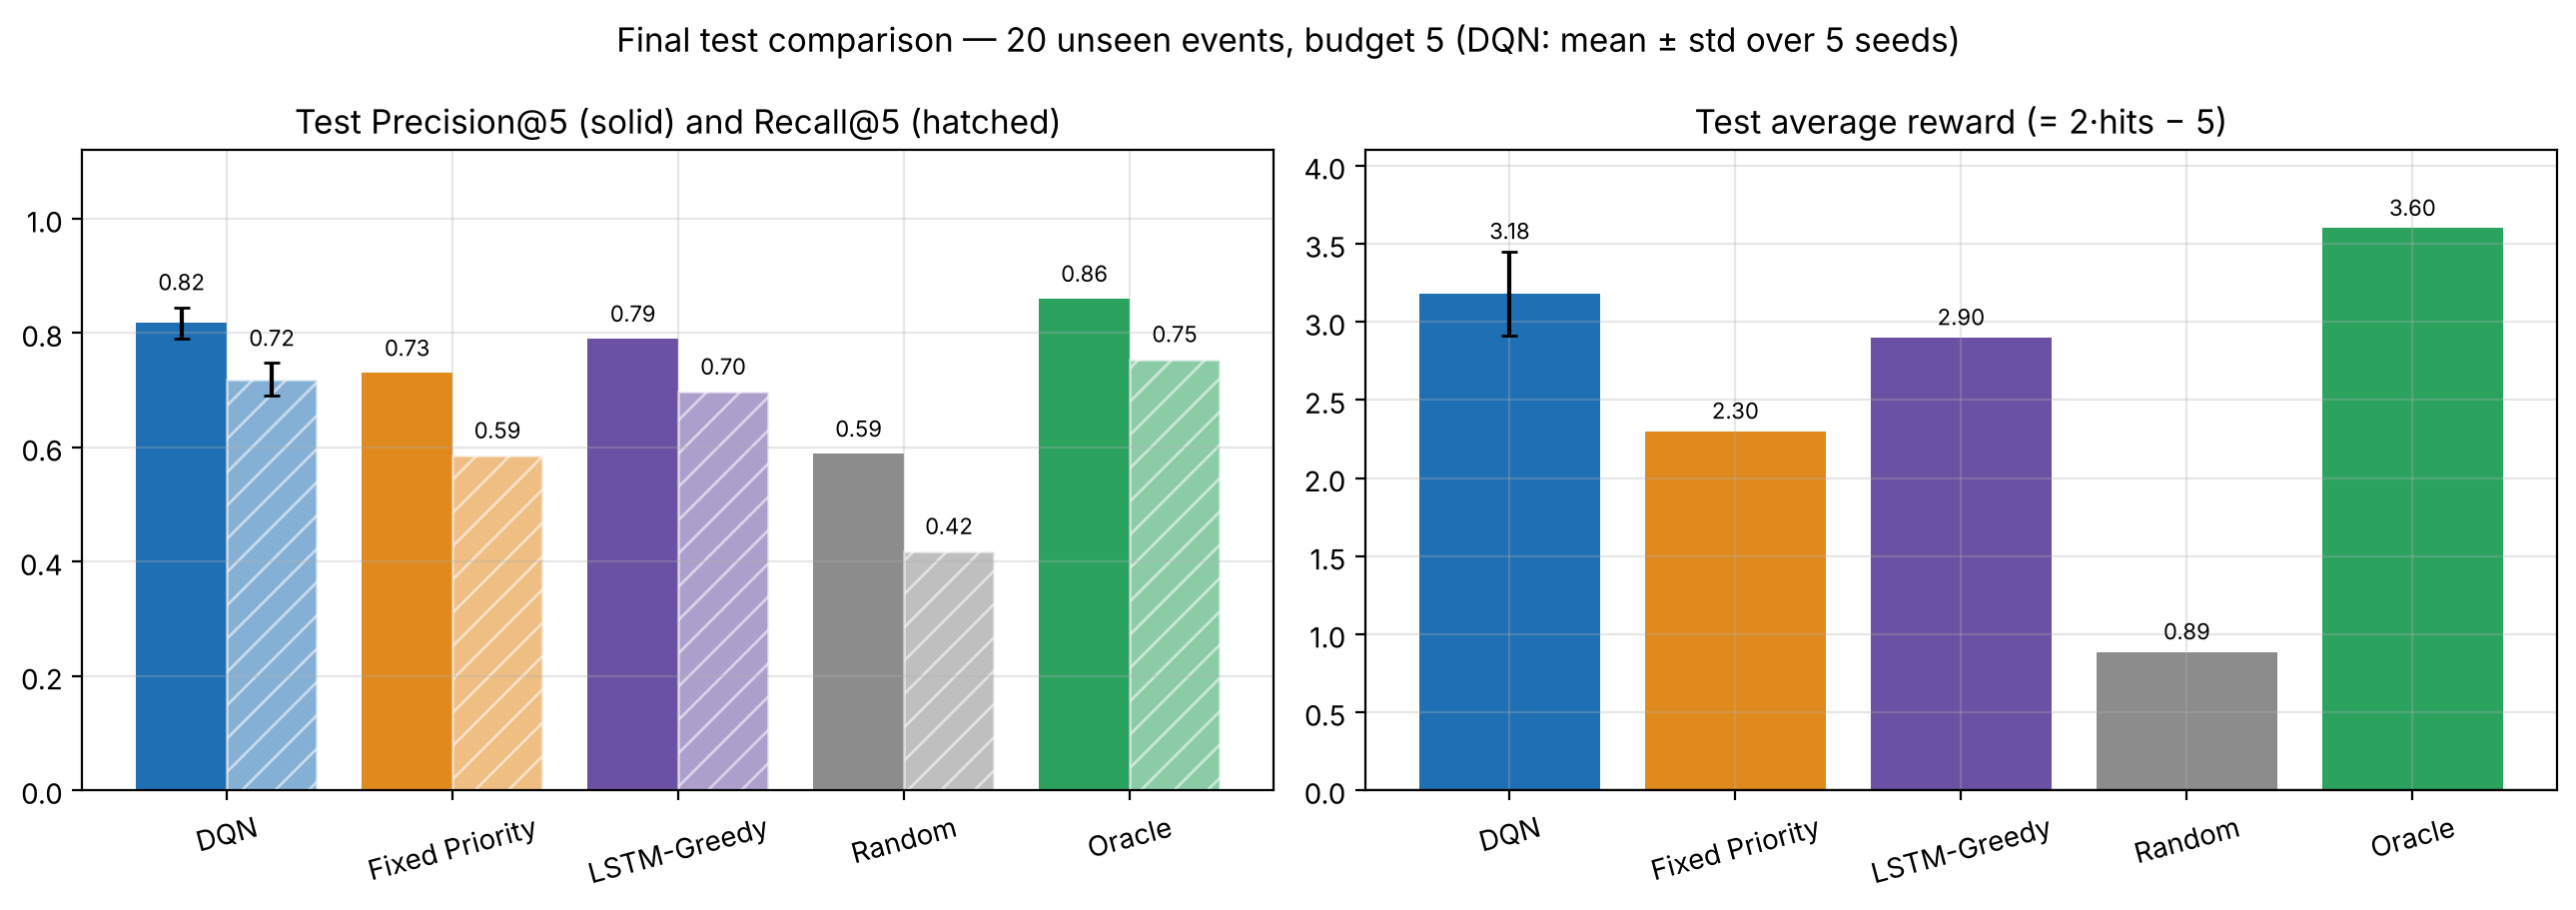

In [5]:
order = ["DQN", "Fixed Priority", "LSTM-Greedy", "Random", "Oracle"]
colors = ["#1f6fb4", "#e08a1e", "#6a51a3", "#8c8c8c", "#2ca25f"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
t = test_cmp.set_index("Method").loc[order]; x = np.arange(len(order))
ax[0].bar(x - 0.2, t["Precision_at_5"], 0.4, yerr=t["Precision_at_5_std"].where(t["Precision_at_5_std"] > 0), capsize=3, color=colors, label="Precision@5")
ax[0].bar(x + 0.2, t["Recall_at_5"], 0.4, yerr=t["Recall_at_5_std"].where(t["Recall_at_5_std"] > 0), capsize=3, color=colors, alpha=0.55, hatch="//", edgecolor="white", label="Recall@5")
for i, m in enumerate(order):
    ax[0].text(i - 0.2, t.loc[m, "Precision_at_5"] + t.loc[m, "Precision_at_5_std"] + 0.03, f'{t.loc[m, "Precision_at_5"]:.2f}', ha="center", fontsize=8)
    ax[0].text(i + 0.2, t.loc[m, "Recall_at_5"] + t.loc[m, "Recall_at_5_std"] + 0.03, f'{t.loc[m, "Recall_at_5"]:.2f}', ha="center", fontsize=8)
ax[0].set_xticks(x, order, rotation=15); ax[0].set_ylim(0, 1.12); ax[0].set_title("Test Precision@5 (solid) and Recall@5 (hatched)")
ax[1].bar(x, t["TotalReward"], yerr=t["TotalReward_std"].where(t["TotalReward_std"] > 0), capsize=3, color=colors)
for i, m in enumerate(order):
    ax[1].text(i, t.loc[m, "TotalReward"] + t.loc[m, "TotalReward_std"] + 0.08, f'{t.loc[m, "TotalReward"]:.2f}', ha="center", fontsize=8)
ax[1].set_ylim(0, 4.1); ax[1].axhline(0, color="black", lw=0.8); ax[1].set_xticks(x, order, rotation=15); ax[1].set_title("Test average reward (= 2·hits − 5)")
fig.suptitle(f"Final test comparison — {int(t.loc['DQN','Cases'])} unseen events, budget 5 (DQN: mean ± std over {len(seeds)} seeds)")
plt.tight_layout(); plt.savefig(PLOTS / "15_final_test_summary.png", bbox_inches="tight"); plt.close()
display(Image(filename=str(PLOTS / "15_final_test_summary.png")))

## 4. Main result: 5-fold cross-validation over all 130 investigation cases (budget 5)
The fixed split above has only 20 test events. Cross-validation tests every case exactly once
(5 seeds per fold, checkpoint chosen on an inner validation split). The state configuration was selected on
inner-validation reward only; the synopsis configuration (raw channel errors) was selected.

In [6]:
best = ext_cfg["best_config"]
cvb = abl[abl.Config == best].copy()
print("Selected configuration:", best, "| inner-validation rewards:", ext_cfg["inner_val_reward"])
print(fmt(cvb).to_string(index=False))
print("\nPaired tests (per-case hits, DQN averaged over seeds, 95 % bootstrap CI of the mean difference):")
print(abl_t[abl_t.Config == best].drop(columns="Config").round(4).to_string(index=False))
print("\nAblation (DQN only):")
print(abl[abl.Method == "DQN"][["Config", "Cases", "TotalReward", "Precision_at_5", "Recall_at_5"]].round(4).to_string(index=False))
print("\nBudget sweep (values are Precision/Recall at the given budget):")
print(sweep.pivot(index="Method", columns="Budget", values="Precision_at_5").round(3).loc[order].to_string())
print("\nAnomaly-score variants (window level):")
print(detcmp.round(4).to_string(index=False))

Selected configuration: (i) original detector + raw state | inner-validation rewards: {'(i) original detector + raw state': 3.666666666666666, '(ii) original detector + normalised state': 3.384761904761904}
        Method  Cases   TotalReward          Hits Precision_at_5   Recall_at_5 UnnecessaryInvestigations
           DQN    130 3.274 ± 0.051 4.137 ± 0.025  0.827 ± 0.005 0.760 ± 0.005             0.863 ± 0.025
Fixed Priority    130         1.615         3.308          0.662         0.557                     1.692
   LSTM-Greedy    130         2.862         3.931          0.786         0.698                     1.069
        Random    130         0.359         2.679          0.536         0.417                     2.321
        Oracle    130         3.738         4.369          0.874         0.810                     0.631

Paired tests (per-case hits, DQN averaged over seeds, 95 % bootstrap CI of the mean difference):
           Comparison  Mean_hit_diff  CI95_low  CI95_high  DQN_be

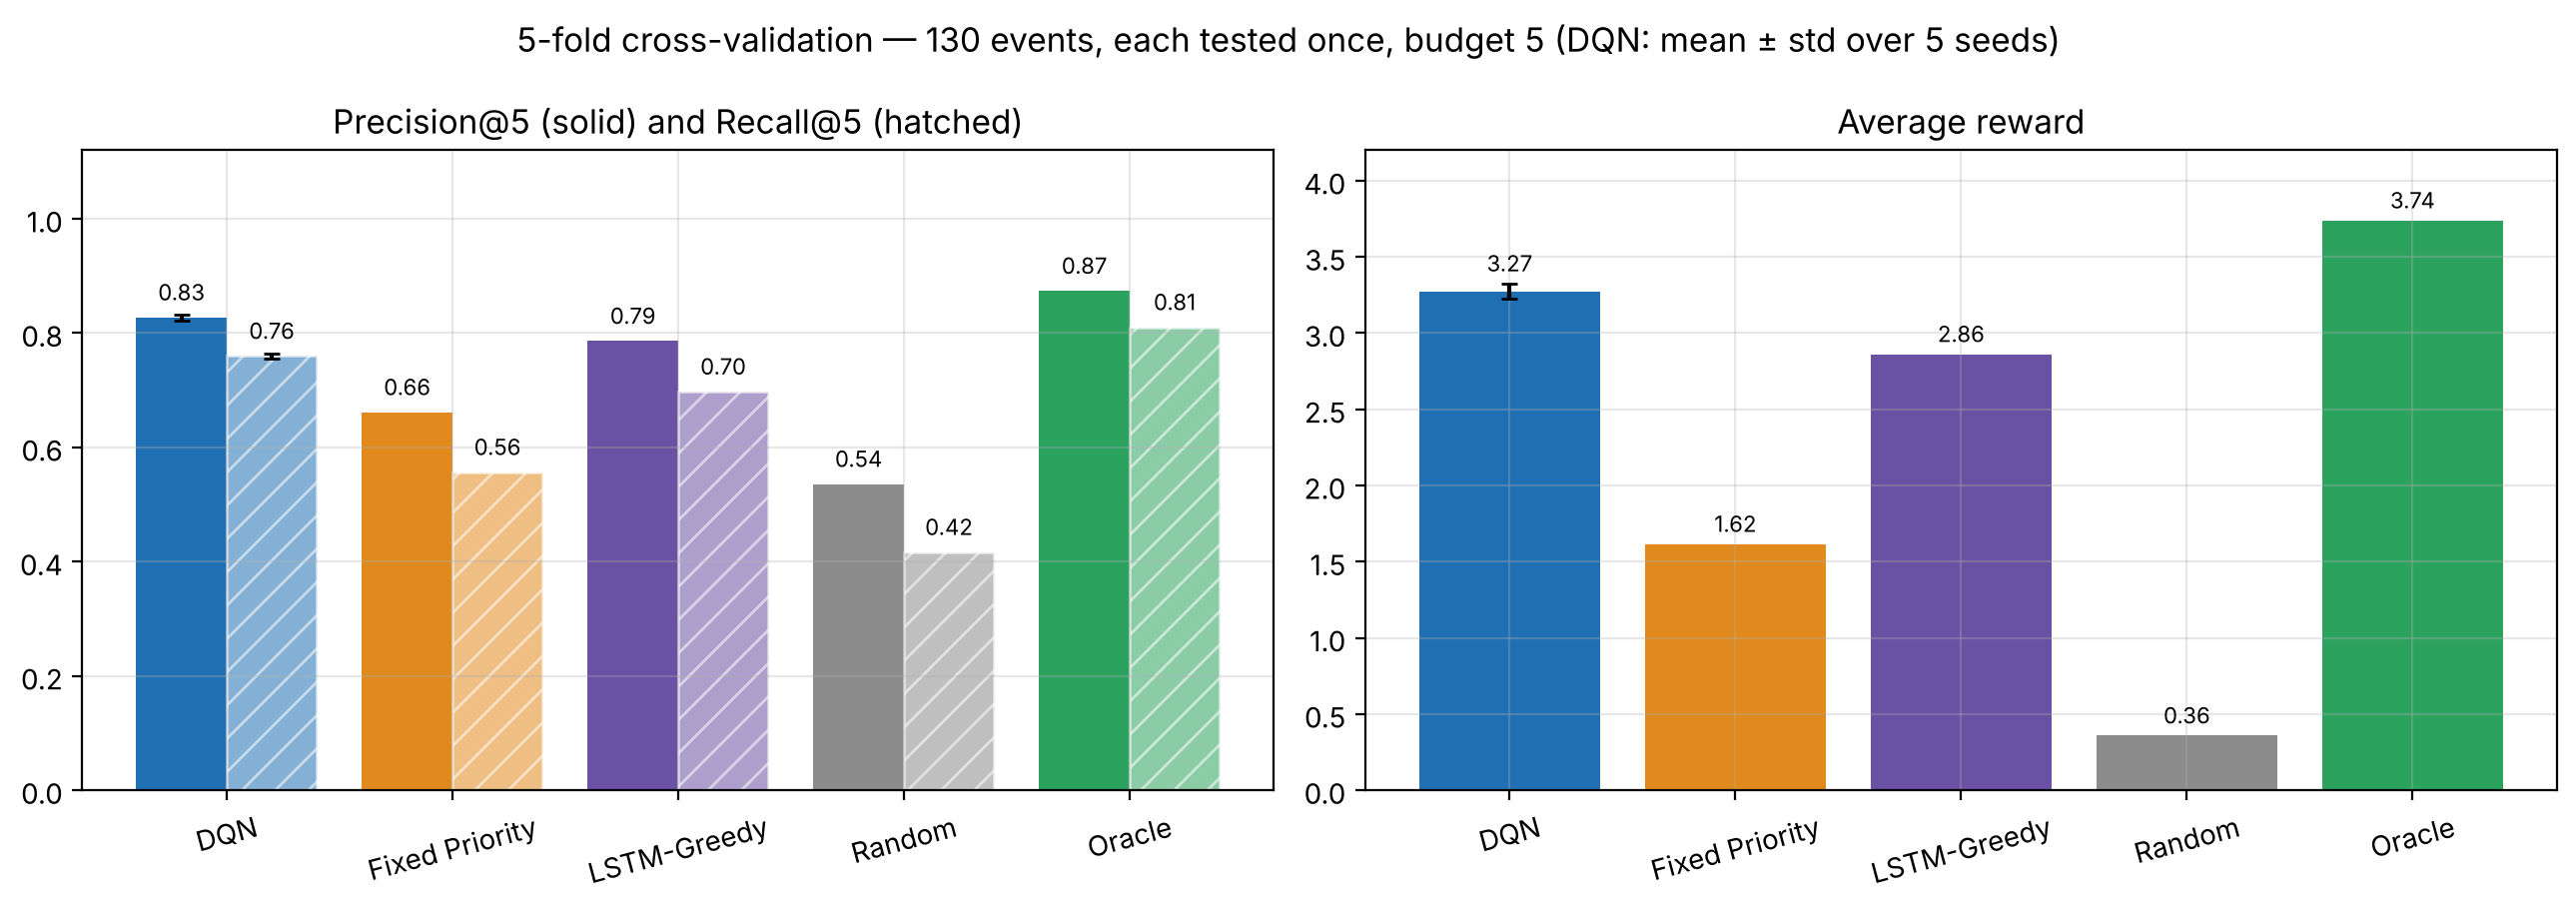

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
t = cvb.set_index("Method").loc[order]; x = np.arange(len(order))
ax[0].bar(x - 0.2, t["Precision_at_5"], 0.4, yerr=t["Precision_at_5_std"].where(t["Precision_at_5_std"] > 0), capsize=3, color=colors)
ax[0].bar(x + 0.2, t["Recall_at_5"], 0.4, yerr=t["Recall_at_5_std"].where(t["Recall_at_5_std"] > 0), capsize=3, color=colors, alpha=0.55, hatch="//", edgecolor="white")
for i, m in enumerate(order):
    ax[0].text(i - 0.2, t.loc[m, "Precision_at_5"] + 0.03, f'{t.loc[m, "Precision_at_5"]:.2f}', ha="center", fontsize=8)
    ax[0].text(i + 0.2, t.loc[m, "Recall_at_5"] + 0.03, f'{t.loc[m, "Recall_at_5"]:.2f}', ha="center", fontsize=8)
ax[0].set_xticks(x, order, rotation=15); ax[0].set_ylim(0, 1.12); ax[0].set_title("Precision@5 (solid) and Recall@5 (hatched)")
ax[1].bar(x, t["TotalReward"], yerr=t["TotalReward_std"].where(t["TotalReward_std"] > 0), capsize=3, color=colors)
for i, m in enumerate(order):
    ax[1].text(i, t.loc[m, "TotalReward"] + t.loc[m, "TotalReward_std"] + 0.08, f'{t.loc[m, "TotalReward"]:.2f}', ha="center", fontsize=8)
ax[1].set_ylim(0, 4.2); ax[1].set_xticks(x, order, rotation=15); ax[1].set_title("Average reward")
fig.suptitle(f"5-fold cross-validation — {int(t.loc['DQN','Cases'])} events, each tested once, budget 5 (DQN: mean ± std over 5 seeds)")
plt.tight_layout(); plt.savefig(PLOTS / "20_final_cv_summary.png", bbox_inches="tight"); plt.close()
display(Image(filename=str(PLOTS / "20_final_cv_summary.png")))

## 5. Final result: improved pipeline (overlapping-window detection + training augmentation)
Same methodology and the same trained LSTM, frozen threshold, DQN, state, reward and budget. Windows are scored every
48 min instead of every 3.2 h, and the DQN trains on all detected windows of each training event (chosen on inner
validation). Each case is still tested exactly once in 5-fold cross-validation.

In [8]:
print("Event coverage (non-overlapping → overlapping windows):"); print(cov.to_string())
print("\nChosen on inner validation:", imp_cfg["chosen"], imp_cfg["inner_val_reward"])
print(fmt(imp).to_string(index=False))
print("\nPaired tests:"); print(imp_t.round(4).to_string(index=False))
print("\nEnd-to-end over all 168 events (undetected events count as 0 found):")
print(e2e[["Pipeline", "Method", "Events_investigated", "E2E_Recall@5", "E2E_Hits_per_event"]].round(4).to_string(index=False))
print("\nBudget sweep (Precision at budget):")
print(imp_sw.pivot(index="Method", columns="Budget", values="Precision_at_5").round(3).loc[order].to_string())

Event coverage (non-overlapping → overlapping windows):
            Old  New  Events
Split                       
Train        90   95     117
Validation   20   23      25
Test         20   20      26
Total       130  138     168

Chosen on inner validation: overlapping windows + training augmentation {'plain': 3.1600000000000006, 'augmented': 3.2181818181818183}
        Method  Cases   TotalReward          Hits Precision_at_5   Recall_at_5 UnnecessaryInvestigations
           DQN    138 3.246 ± 0.051 4.123 ± 0.026  0.825 ± 0.005 0.775 ± 0.006             0.877 ± 0.026
Fixed Priority    138         1.609         3.304          0.661         0.575                     1.696
   LSTM-Greedy    138         2.739         3.870          0.774         0.702                     1.130
        Random    138         0.248         2.624          0.525         0.417                     2.376
        Oracle    138         3.609         4.304          0.861         0.817                     0.696

Pai

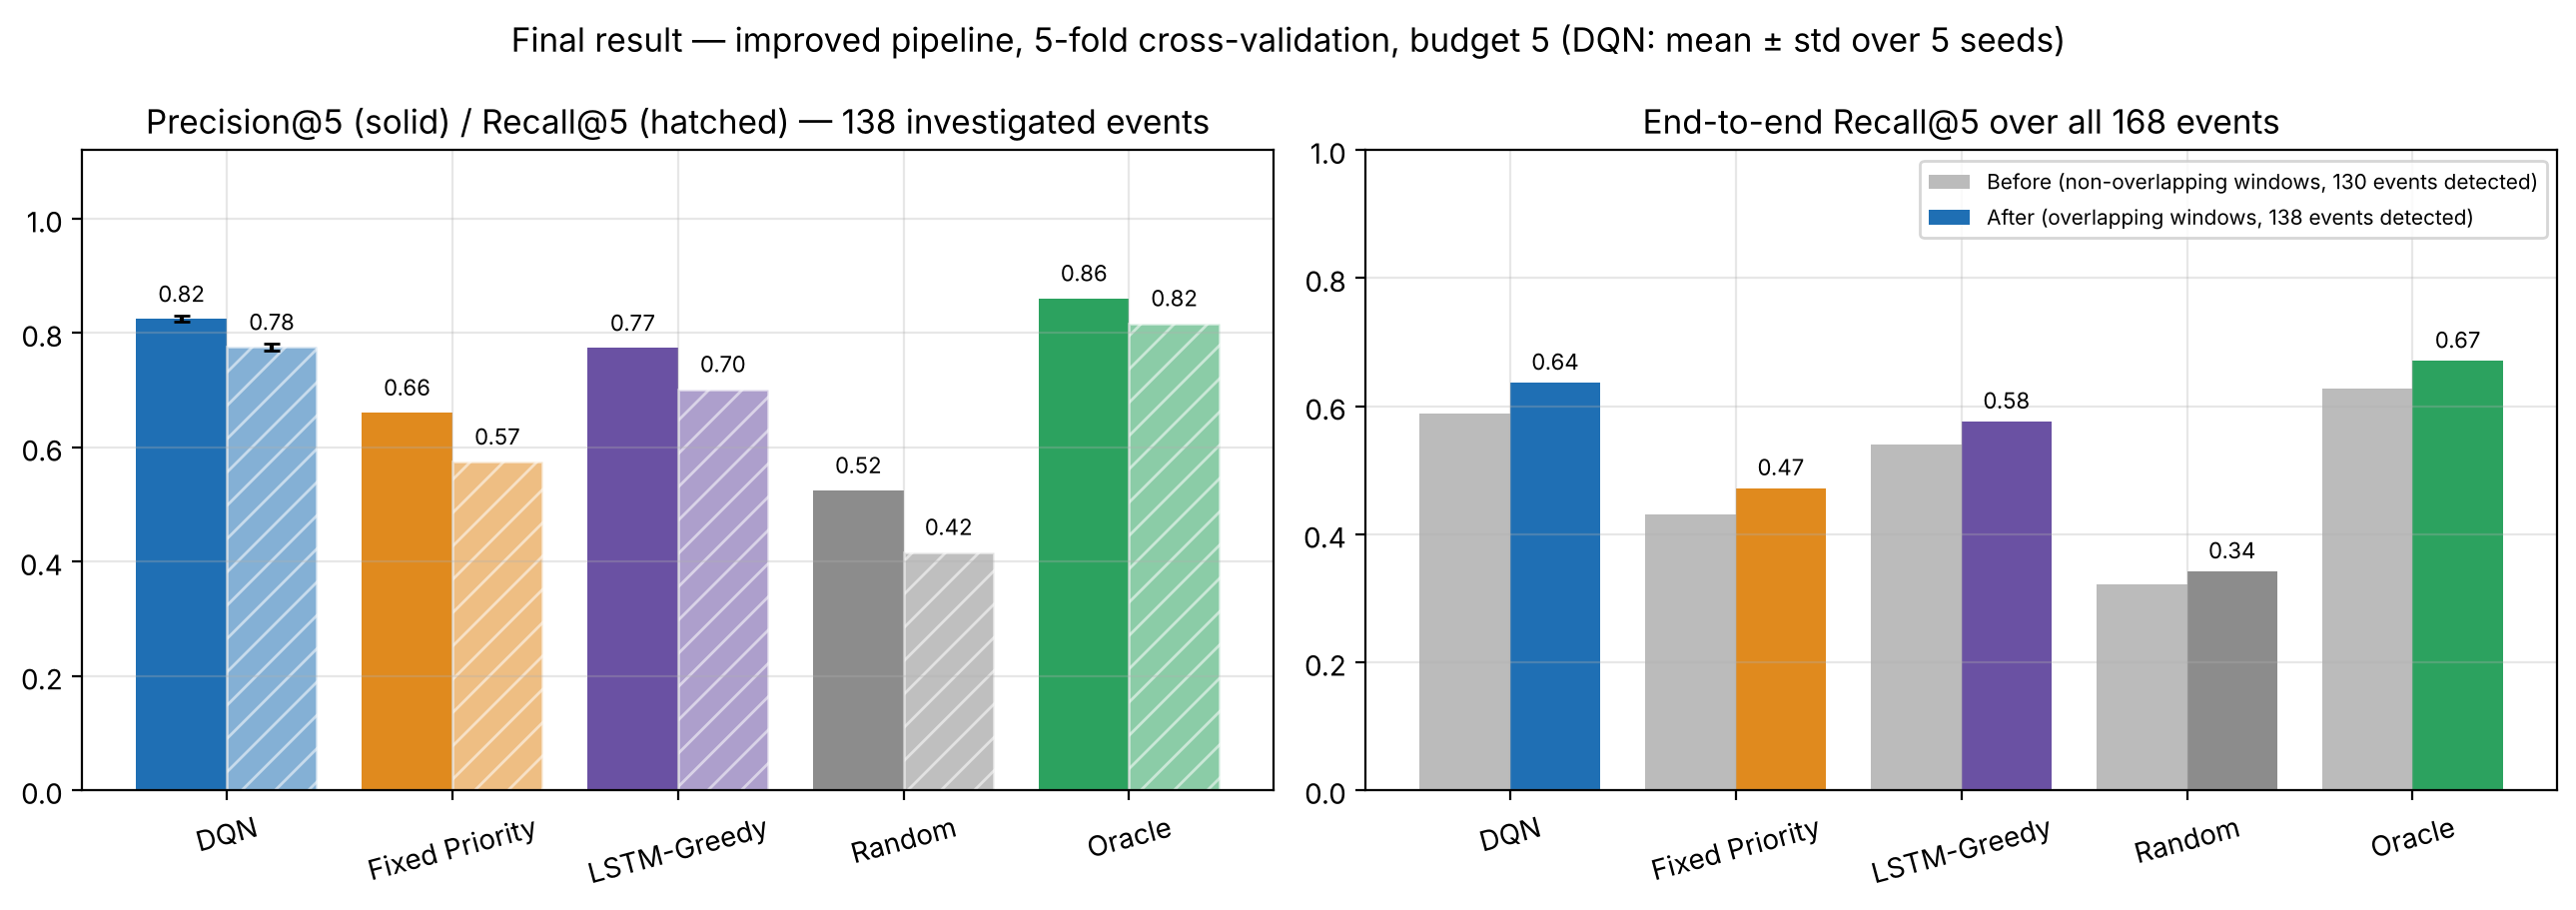

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
t = imp.set_index("Method").loc[order]; x = np.arange(len(order))
ax[0].bar(x - 0.2, t["Precision_at_5"], 0.4, yerr=t["Precision_at_5_std"].where(t["Precision_at_5_std"] > 0), capsize=3, color=colors)
ax[0].bar(x + 0.2, t["Recall_at_5"], 0.4, yerr=t["Recall_at_5_std"].where(t["Recall_at_5_std"] > 0), capsize=3, color=colors, alpha=0.55, hatch="//", edgecolor="white")
for i, m in enumerate(order):
    ax[0].text(i - 0.2, t.loc[m, "Precision_at_5"] + 0.03, f'{t.loc[m, "Precision_at_5"]:.2f}', ha="center", fontsize=8)
    ax[0].text(i + 0.2, t.loc[m, "Recall_at_5"] + 0.03, f'{t.loc[m, "Recall_at_5"]:.2f}', ha="center", fontsize=8)
ax[0].set_xticks(x, order, rotation=15); ax[0].set_ylim(0, 1.12)
ax[0].set_title(f"Precision@5 (solid) / Recall@5 (hatched) — {int(t.loc['DQN','Cases'])} investigated events")
pv = e2e.pivot(index="Method", columns="Pipeline", values="E2E_Recall@5").loc[order]
before, after = [c for c in pv.columns if c.startswith("Notebook")][0], [c for c in pv.columns if c.startswith("Improved")][0]
ax[1].bar(x - 0.2, pv[before], 0.4, color="#bbbbbb", label="Before (non-overlapping windows, 130 events detected)")
ax[1].bar(x + 0.2, pv[after], 0.4, color=colors, label="After (overlapping windows, 138 events detected)")
for i, m in enumerate(order):
    ax[1].text(i + 0.2, pv.loc[m, after] + 0.02, f"{pv.loc[m, after]:.2f}", ha="center", fontsize=8)
ax[1].set_xticks(x, order, rotation=15); ax[1].set_ylim(0, 1); ax[1].legend(fontsize=7.5, loc="upper right")
ax[1].set_title("End-to-end Recall@5 over all 168 events")
fig.suptitle("Final result — improved pipeline, 5-fold cross-validation, budget 5 (DQN: mean ± std over 5 seeds)")
plt.tight_layout(); plt.savefig(PLOTS / "23_final_improved_summary.png", bbox_inches="tight"); plt.close()
display(Image(filename=str(PLOTS / "23_final_improved_summary.png")))

## 6. Interpretation (generated from the numbers above)

In [10]:
g = lambda m, k: float(test_cmp.set_index("Method").loc[m, k])
d, f, l, r, o = "DQN", "Fixed Priority", "LSTM-Greedy", "Random", "Oracle"
p_fixed = float(stats.set_index("Comparison").loc["DQN vs Fixed Priority", "Wilcoxon_p"])
p_rand = float(stats.set_index("Comparison").loc["DQN vs Random", "Wilcoxon_p"])
def cmp_word(a, b, tol=0.005):
    return "higher than" if a > b + tol else ("lower than" if a < b - tol else "about equal to")
cvi = cvb.set_index("Method"); cv = lambda m, k: float(cvi.loc[m, k]); n_cv = int(cvi.loc["DQN", "Cases"])
bt = abl_t[abl_t.Config == best].set_index("Comparison"); pt = lambda o: float(bt.loc[f"DQN vs {o}", "Wilcoxon_p"])
ivt = imp.set_index("Method"); iv = lambda m, k: float(ivt.loc[m, k]); ni = int(ivt.loc["DQN", "Cases"])
ipt = imp_t.set_index("Comparison"); ip = lambda o: float(ipt.loc[f"DQN vs {o}", "Wilcoxon_p"])
e2 = lambda pre, m: float(e2e[e2e.Pipeline.str.startswith(pre) & (e2e.Method == m)]["E2E_Recall@5"].iloc[0])
txt = f"""
* The LSTM autoencoder separates label-clean and anomalous windows on unseen test data with PR-AUC
  {lstm.set_index('Split').loc['Test','PR_AUC']:.3f} and ROC-AUC {lstm.set_index('Split').loc['Test','ROC_AUC']:.3f}
  (threshold {lstm_cfg['threshold']:.4f} chosen on validation). {int(det['LSTM_detected_events'].sum())} of
  {int(det['Events'].sum())} events produced at least one detected window and became investigation cases.
* On the {int(g(d,'Cases'))} test cases the DQN reaches Precision@5 {g(d,'Precision_at_5'):.3f} ± {g(d,'Precision_at_5_std'):.3f},
  Recall@5 {g(d,'Recall_at_5'):.3f} and average reward {g(d,'TotalReward'):.2f}.
* DQN vs Random: Precision@5 {g(d,'Precision_at_5'):.3f} vs {g(r,'Precision_at_5'):.3f} (Wilcoxon p = {p_rand:.3g}).
* DQN vs Fixed priority: Precision@5 is {cmp_word(g(d,'Precision_at_5'), g(f,'Precision_at_5'))} the fixed ranking
  ({g(f,'Precision_at_5'):.3f}); the paired test gives p = {p_fixed:.3g}, so
  {'the difference is statistically significant at α = 0.05' if p_fixed < 0.05 else 'the difference is not statistically significant at α = 0.05'}.
* LSTM-greedy (top-5 reconstruction errors) reaches Precision@5 {g(l,'Precision_at_5'):.3f}; the Oracle upper bound is
  {g(o,'Precision_at_5'):.3f} (limited by events with fewer than 5 annotated channels).
* **Cross-validated main result (all {n_cv} cases, budget 5):** DQN Precision@5 {cv('DQN','Precision_at_5'):.3f} ± {cv('DQN','Precision_at_5_std'):.3f},
  Recall@5 {cv('DQN','Recall_at_5'):.3f}, reward {cv('DQN','TotalReward'):.2f}; LSTM-greedy {cv('LSTM-Greedy','Precision_at_5'):.3f},
  Fixed priority {cv('Fixed Priority','Precision_at_5'):.3f}, Random {cv('Random','Precision_at_5'):.3f}, Oracle {cv('Oracle','Precision_at_5'):.3f}.
  Paired Wilcoxon p-values: vs LSTM-greedy {pt('LSTM-Greedy'):.3g}, vs Fixed priority {pt('Fixed Priority'):.3g}, vs Random {pt('Random'):.3g}.
* The budget sweep shows DQN at or above every baseline for budgets 3, 5 and 7 (Precision {', '.join(f"{v:.3f}" for v in sweep[sweep.Method=='DQN'].sort_values('Budget').Precision_at_5)}).
* Normalising channel errors improves window-level anomaly detection (test PR-AUC {detcmp.query("Score=='Mean MSE (original)' and Split=='Test'").PR_AUC.iloc[0]:.3f} →
  {detcmp.query("Score=='Max log-ratio' and Split=='Test'").PR_AUC.iloc[0]:.3f}) but does not improve the investigation stage, so the synopsis
  configuration (raw channel errors in the DQN state) is retained, as selected on inner validation.
* **Final improved pipeline (overlapping windows + training augmentation, {ni} events, budget 5):** DQN Precision@5
  {iv('DQN','Precision_at_5'):.3f} ± {iv('DQN','Precision_at_5_std'):.3f}, Recall@5 {iv('DQN','Recall_at_5'):.3f}, reward {iv('DQN','TotalReward'):.2f};
  LSTM-greedy {iv('LSTM-Greedy','Precision_at_5'):.3f}, Fixed priority {iv('Fixed Priority','Precision_at_5'):.3f}, Random {iv('Random','Precision_at_5'):.3f},
  Oracle {iv('Oracle','Precision_at_5'):.3f}. Wilcoxon p: vs LSTM-greedy {ip('LSTM-Greedy'):.3g}, vs Fixed {ip('Fixed Priority'):.3g}, vs Random {ip('Random'):.3g}.
* End-to-end over all 168 events, DQN Recall@5 rises from {e2('Notebook', 'DQN'):.3f} to {e2('Improved', 'DQN'):.3f}.
  The remaining undetected events are mostly very short (median well under one hour), shorter than one LSTM window.
* Annotations indicate event association, not proven causal root causes; reward is computed from them offline only.
"""
display(Markdown(txt)); (RES / "final_interpretation.md").write_text(txt)


* The LSTM autoencoder separates label-clean and anomalous windows on unseen test data with PR-AUC
  0.517 and ROC-AUC 0.745
  (threshold 0.0186 chosen on validation). 130 of
  168 events produced at least one detected window and became investigation cases.
* On the 20 test cases the DQN reaches Precision@5 0.818 ± 0.027,
  Recall@5 0.719 and average reward 3.18.
* DQN vs Random: Precision@5 0.818 vs 0.589 (Wilcoxon p = 0.00203).
* DQN vs Fixed priority: Precision@5 is higher than the fixed ranking
  (0.730); the paired test gives p = 0.08, so
  the difference is not statistically significant at α = 0.05.
* LSTM-greedy (top-5 reconstruction errors) reaches Precision@5 0.790; the Oracle upper bound is
  0.860 (limited by events with fewer than 5 annotated channels).
* **Cross-validated main result (all 130 cases, budget 5):** DQN Precision@5 0.827 ± 0.005,
  Recall@5 0.760, reward 3.27; LSTM-greedy 0.786,
  Fixed priority 0.662, Random 0.536, Oracle 0.874.
  Paired Wilcoxon p-values: vs LSTM-greedy 0.00513, vs Fixed priority 1.51e-13, vs Random 5.12e-20.
* The budget sweep shows DQN at or above every baseline for budgets 3, 5 and 7 (Precision 0.933, 0.827, 0.693).
* Normalising channel errors improves window-level anomaly detection (test PR-AUC 0.517 →
  0.628) but does not improve the investigation stage, so the synopsis
  configuration (raw channel errors in the DQN state) is retained, as selected on inner validation.
* **Final improved pipeline (overlapping windows + training augmentation, 138 events, budget 5):** DQN Precision@5
  0.825 ± 0.005, Recall@5 0.775, reward 3.25;
  LSTM-greedy 0.774, Fixed priority 0.661, Random 0.525,
  Oracle 0.861. Wilcoxon p: vs LSTM-greedy 0.000624, vs Fixed 5.85e-15, vs Random 7.99e-22.
* End-to-end over all 168 events, DQN Recall@5 rises from 0.588 to 0.637.
  The remaining undetected events are mostly very short (median well under one hour), shorter than one LSTM window.
* Annotations indicate event association, not proven causal root causes; reward is computed from them offline only.


2060